<a href="https://colab.research.google.com/github/arambhaghimirecs24-stack/BIS/blob/main/1BF24CS062_Grey_Wolf_Optimizer/1BF24CS062_Grey_Wolf_Optimizer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Best Path:
[[0.00000000e+00 0.00000000e+00]
 [1.30004960e-06 6.45731090e-05]
 [5.58927781e-01 4.43568596e-06]
 [3.94173565e+00 3.06714037e+00]
 [4.00000000e+00 6.00000000e+00]]

Best Fitness: 8.058901889513615


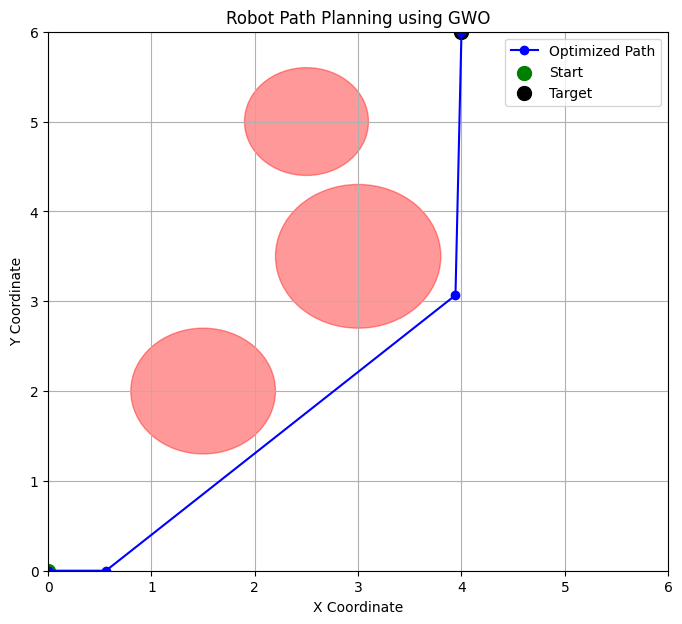

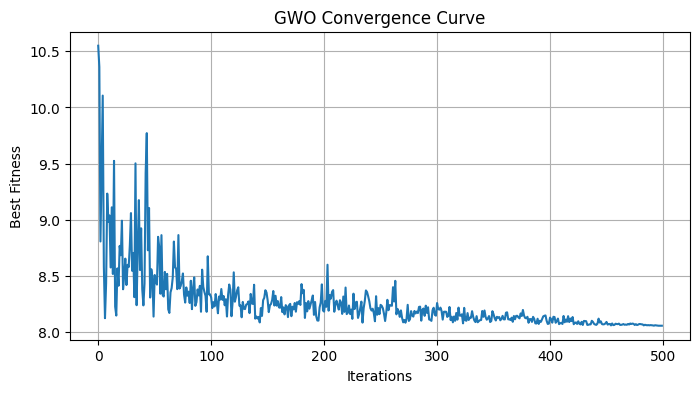

In [3]:

import numpy as np
import matplotlib.pyplot as plt

np.random.seed(10)

start = np.array([0.0, 0.0])
target = np.array([4.0, 6.0])

obstacles = [
    (1.5, 2.0, 0.7),
    (3.0, 3.5, 0.8),
    (2.5, 5.0, 0.6)
]

wolves = 50
iterations = 500
dimensions = 6
lower_bound = 0
upper_bound = 6
beta = 1000
clearance = 0.15

def get_path(position):
    points = position.reshape(3, 2)
    return np.vstack((start, points, target))

def distance_to_segment(point, a, b):
    ab = b - a
    denominator = np.dot(ab, ab)

    if denominator == 0:
        return np.linalg.norm(point - a)

    t = np.dot(point - a, ab) / denominator
    t = np.clip(t, 0, 1)
    closest = a + t * ab

    return np.linalg.norm(point - closest)

def fitness(position):
    path = get_path(position)

    distance = 0
    penalty = 0

    for i in range(len(path) - 1):
        distance += np.linalg.norm(path[i + 1] - path[i])

        for ox, oy, radius in obstacles:
            obstacle_center = np.array([ox, oy])

            min_distance = distance_to_segment(
                obstacle_center, path[i], path[i + 1]
            )

            safe_radius = radius + clearance

            if min_distance < safe_radius:
                penalty += (safe_radius - min_distance) ** 2

    return distance + beta * penalty

# Initialize wolves
population = np.random.uniform(
    lower_bound, upper_bound, (wolves, dimensions)
)

alpha_pos = np.zeros(dimensions)
beta_pos = np.zeros(dimensions)
delta_pos = np.zeros(dimensions)

alpha_score = float("inf")
beta_score = float("inf")
delta_score = float("inf")

convergence = []

# GWO main loop
for iteration in range(iterations):

    alpha_score = float("inf")
    beta_score = float("inf")
    delta_score = float("inf")

    for i in range(wolves):

        score = fitness(population[i])

        if score < alpha_score:
            delta_score = beta_score
            delta_pos = beta_pos.copy()

            beta_score = alpha_score
            beta_pos = alpha_pos.copy()

            alpha_score = score
            alpha_pos = population[i].copy()

        elif score < beta_score:
            delta_score = beta_score
            delta_pos = beta_pos.copy()

            beta_score = score
            beta_pos = population[i].copy()

        elif score < delta_score:
            delta_score = score
            delta_pos = population[i].copy()

    a = 2 - 2 * iteration / iterations

    for i in range(wolves):

        for j in range(dimensions):

            r1 = np.random.random()
            r2 = np.random.random()

            A1 = 2 * a * r1 - a
            C1 = 2 * r2

            D_alpha = abs(C1 * alpha_pos[j] - population[i][j])
            X1 = alpha_pos[j] - A1 * D_alpha

            r1 = np.random.random()
            r2 = np.random.random()

            A2 = 2 * a * r1 - a
            C2 = 2 * r2

            D_beta = abs(C2 * beta_pos[j] - population[i][j])
            X2 = beta_pos[j] - A2 * D_beta

            r1 = np.random.random()
            r2 = np.random.random()

            A3 = 2 * a * r1 - a
            C3 = 2 * r2

            D_delta = abs(C3 * delta_pos[j] - population[i][j])
            X3 = delta_pos[j] - A3 * D_delta

            population[i][j] = (X1 + X2 + X3) / 3

        population[i] = np.clip(
            population[i], lower_bound, upper_bound
        )

    convergence.append(alpha_score)

# Best path
best_path = get_path(alpha_pos)

print("Best Path:")
print(best_path)

print("\nBest Fitness:", alpha_score)

# Plot optimized path
plt.figure(figsize=(8, 7))

for ox, oy, radius in obstacles:
    circle = plt.Circle(
        (ox, oy), radius,
        color="red", alpha=0.4
    )
    plt.gca().add_patch(circle)

plt.plot(
    best_path[:, 0],
    best_path[:, 1],
    "b-o",
    label="Optimized Path"
)

plt.scatter(*start, color="green", s=100, label="Start")
plt.scatter(*target, color="black", s=100, label="Target")

plt.xlim(0, 6)
plt.ylim(0, 6)
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.title("Robot Path Planning using GWO")
plt.legend()
plt.grid()
plt.show()

# Convergence graph
plt.figure(figsize=(8, 4))
plt.plot(convergence)
plt.xlabel("Iterations")
plt.ylabel("Best Fitness")
plt.title("GWO Convergence Curve")
plt.grid()
plt.show()
